# 03 – Part 2: tuning (and the TwoTower model)

Hyperparameter tuning of the Part 2 models on the **validation split**. The test evaluation, the variability,
the disaggregated results and the sparsity ablation are done separately (`src/part2_analysis.py`).

| Model | Paradigm | Implementation |
|---|---|---|
| UserKNN | Neighbourhood CF | **self-implemented** (`src/model/simple_models.py`) |
| ImplicitALS | Latent-factor CF | library `implicit` |
| ImplicitBPR | Ranking-loss CF | library `implicit` |
| TwoTower | Neural | **self-implemented** in PyTorch (`src/model/two_tower.py`) |

The Part 1 baselines (MostPopular, ItemKNN) were tuned in `02_tuning.ipynb`. The search code is in
`src/tuning.py`.

**Protocol** (the same as in Part 1)
- Trained on `train`, scored on `val`; **the test split is not used here** (it only appears in the user counts
  below). Every model gets the same Optuna budget.
- Full-catalogue ranking, relevant = rating >= 4, cut-off 10, users without history are included (as in Part 1).

**Runtime** (one CPU thread): about 2 hours, most of it TwoTower and UserKNN.

In [1]:
import os
import sys
import time
from pathlib import Path

import yaml

# Works whether the notebook is started from the repo root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

cfg = yaml.safe_load((ROOT / "config.yaml").read_text())
DATA_DIR = Path(os.environ.get("DATA_DIR", ROOT / "data" / "ml-1m"))
RESULTS_DIR = ROOT / "results"
print("ROOT:", ROOT)
print("DATA_DIR:", DATA_DIR)

ROOT: /home/jindra/Documents/DATA.ML.360-2026-2027-1_group16
DATA_DIR: /home/jindra/Documents/DATA.ML.360-2026-2027-1_group16/data/ml-1m


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd

from src import tuning
from src.data.splitting import split
from src.evaluation import evaluate_recommender
from src.model import Dataset
from src.model.two_tower import TwoTower

optuna.logging.set_verbosity(optuna.logging.WARNING)  # tuning.tune prints one line per trial
pd.set_option("display.max_colwidth", 200)

# One fixed colour per model (the same in every plot), validated for colour-blind readers
COLORS = {"MostPopular": "#2a78d6", "ItemKNN": "#eb6834", "UserKNN": "#1baf7a",
          "ImplicitALS": "#eda100", "ImplicitBPR": "#e87ba4", "TwoTower": "#008300"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e5e5e5", "grid.linewidth": 0.6, "lines.linewidth": 2})

/home/jindra/Documents/DATA.ML.360-2026-2027-1_group16/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Settings

Everything comes from `config.yaml` (`evaluation`, `seed` and the `part2` section). The number of trials can be
overridden with the environment variable `PART2_N_TRIALS` for a quick test run.

In [3]:
K = cfg["evaluation"]["k"]
THRESHOLD = cfg["evaluation"]["relevance_threshold"]
SEED = cfg["seed"]
P2 = cfg["part2"]
N_TRIALS = int(os.environ.get("PART2_N_TRIALS", P2["tuning_trials"]))
TUNED_MODELS = [name for name, spec in tuning.MODELS.items() if spec.search_space is not None]

print(f"K={K}, threshold={THRESHOLD}, seed={SEED}, trials per model={N_TRIALS}")
print("tuned here:", TUNED_MODELS)

K=10, threshold=4, seed=42, trials per model=30
tuned here: ['UserKNN', 'ImplicitALS', 'ImplicitBPR', 'TwoTower']
test seeds: [42, 43, 44, 45, 46] | sparsity: [1.0, 0.5, 0.2] seeds [42, 43, 44]


## Data and split

In [4]:
ds = Dataset.from_config(DATA_DIR, cfg["load"])
s = split(ds, cfg["split"])
print(s.summary())

CATALOGUE = set(ds.movies["item_id"])  # full catalogue: every movie in movies.dat
# For the test runs the models are trained on train + validation (as in run_all.py)
history = s.train.with_ratings(pd.concat([s.train.ratings, s.val.ratings], ignore_index=True))
test = s.test.ratings

train   800168 rows  2000-04-25 -> 2000-12-02
val     100020 rows  2000-12-02 -> 2000-12-29
test    100021 rows  2000-12-29 -> 2003-02-28


**Tuning objective: NDCG@10 of users with history.** Validation covers only one month right after train, so
more than half of its evaluated users have no train ratings. In test (with train + validation as history)
almost every user has history. Tuning on all validation users would mostly pick the configuration that is
best for new users, which are a tiny part of test. So the objective is NDCG@10 of validation users who have
train ratings (`ndcg_warm`); the overall NDCG and the new users are still recorded on every trial. For
UserKNN, ALS and BPR this changes nothing, because they recommend nothing to new users (their overall NDCG is
the warm NDCG times a constant). It matters for TwoTower, which can use the demographics of new users.

In [5]:
def warm_cold(history_ratings, eval_ratings):
    users = set(eval_ratings.loc[eval_ratings["rating"] >= THRESHOLD, "user_id"])
    warm = len(users & set(history_ratings["user_id"]))
    return {"evaluated users": len(users), "with history": warm, "new users": len(users) - warm,
            "share new": round((len(users) - warm) / len(users), 3)}

pd.DataFrame({"validation (history = train)": warm_cold(s.train.ratings, s.val.ratings),
              "test (history = train + val)": warm_cold(history.ratings, test)}).T

,evaluated users,with history,new users,share new
validation (history = train),1103.0,492.0,611.0,0.554
test (history = train + val),1188.0,1159.0,29.0,0.024


## 1. Tuning on validation

Search spaces: `src/tuning.py` (`user_knn_space`, `als_space`, `bpr_space`, `two_tower_space`). Optuna TPE with a
fixed seed, `N_TRIALS` trials per model, the same budget as ItemKNN got in Part 1. Random models are trained with
the same seed in every trial, so the trials differ only in their hyperparameters.

All trials are saved to `results/part2_tuning_trials.csv` (to report the search and its budget).

In [6]:
studies = {}
for name in TUNED_MODELS:
    start = time.time()
    studies[name] = tuning.tune(name, s.train, s.val.ratings, CATALOGUE, K, THRESHOLD,
                               n_trials=N_TRIALS, seed=SEED)
    print(f"--- {name}: {(time.time() - start) / 60:.0f} min, best ndcg_warm "
          f"{studies[name].best_value:.4f}\n")

trials = pd.concat([tuning.trials_table(study) for study in studies.values()], ignore_index=True)
trials.to_csv(RESULTS_DIR / "part2_tuning_trials.csv", index=False)

UserKNN trial   0: ndcg_warm=0.0745 ndcg=0.0332 coverage=0.065 (53.2 s) k=19, similarity_measure=cosine, gamma=50, min_support=10
UserKNN trial   1: ndcg_warm=0.0088 ndcg=0.0039 coverage=0.040 (59.6 s) k=14, similarity_measure=cosine, gamma=None, min_support=1
UserKNN trial   2: ndcg_warm=0.0425 ndcg=0.0190 coverage=0.181 (63.1 s) k=6, similarity_measure=pearson, gamma=25, min_support=10
UserKNN trial   3: ndcg_warm=0.0600 ndcg=0.0268 coverage=0.070 (42.7 s) k=36, similarity_measure=pearson, gamma=None, min_support=100
UserKNN trial   4: ndcg_warm=0.0051 ndcg=0.0023 coverage=0.041 (63.5 s) k=13, similarity_measure=jaccard, gamma=10, min_support=1
UserKNN trial   5: ndcg_warm=0.0941 ndcg=0.0420 coverage=0.028 (40.5 s) k=119, similarity_measure=cosine, gamma=100, min_support=100
UserKNN trial   6: ndcg_warm=0.0827 ndcg=0.0369 coverage=0.044 (54.6 s) k=33, similarity_measure=cosine, gamma=100, min_support=10
UserKNN trial   7: ndcg_warm=0.0011 ndcg=0.0005 coverage=0.015 (62.1 s) k=154, si

/home/jindra/Documents/DATA.ML.360-2026-2027-1_group16/.venv/lib/python3.11/site-packages/implicit/cpu/als.py:96: RuntimeWarning: OpenBLAS is configured to use 12 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


ImplicitALS trial   0: ndcg_warm=0.1115 ndcg=0.0497 coverage=0.240 (6.1 s) factors=44, regularization=5.669849511478847, alpha=15.702970884055382, iterations=32
ImplicitALS trial   1: ndcg_warm=0.1186 ndcg=0.0529 coverage=0.091 (10.3 s) factors=24, regularization=0.000602521573620386, alpha=0.14936568554617632, iterations=44
ImplicitALS trial   2: ndcg_warm=0.0837 ndcg=0.0373 coverage=0.111 (13.0 s) factors=84, regularization=0.3470266988650412, alpha=0.115279871282324, iterations=49
ImplicitALS trial   3: ndcg_warm=0.0804 ndcg=0.0359 coverage=0.160 (5.4 s) factors=160, regularization=0.0011526449540315614, alpha=0.3511356313970407, iterations=13
ImplicitALS trial   4: ndcg_warm=0.1262 ndcg=0.0563 coverage=0.154 (2.4 s) factors=36, regularization=0.042051564509138675, alpha=1.976218934028007, iterations=18
ImplicitALS trial   5: ndcg_warm=0.1068 ndcg=0.0476 coverage=0.163 (5.8 s) factors=86, regularization=0.0004982752357076451, alpha=0.7523742884534856, iterations=21
ImplicitALS trial

In [7]:
# Best trial of every model, with all validation metrics
metric_cols = ["ndcg_warm", "ndcg", "ndcg_cold", "precision", "recall", "coverage", "seconds"]
best = pd.DataFrame([{"model": name, **study.best_trial.user_attrs,
                      "hyperparameters": tuning.describe(study.best_params)}
                     for name, study in studies.items()])
best[["model", *metric_cols, "hyperparameters"]]

,model,ndcg_warm,ndcg,ndcg_cold,precision,recall,coverage,seconds,hyperparameters
0,UserKNN,0.098977,0.044149,0.00000,0.038713,0.018831,0.034509,49.5,"k=131, similarity_measure=pearson, gamma=100, min_support=100"
1,ImplicitALS,0.133495,0.059546,0.00000,0.051677,0.031817,0.114087,1.3,"factors=16, regularization=0.001306757868853338, alpha=1.1514741512677193, iterations=6"
2,ImplicitBPR,0.143640,0.064071,0.00000,0.052584,0.032144,0.107649,21.9,"factors=99, learning_rate=0.0012368429194827427, regularization=8.597755025873098e-05, iterations=127"
3,TwoTower,0.143524,0.266087,0.36478,0.240888,0.070324,0.087046,134.4,"dim=64, embedding_dim=32, hidden=256, epochs=9, batch_size=1024, learning_rate=0.0003646439558980723, weight_decay=5.169879442298538e-06, temperature=0.0314799191252873, id_dropout=0.4010984903770..."


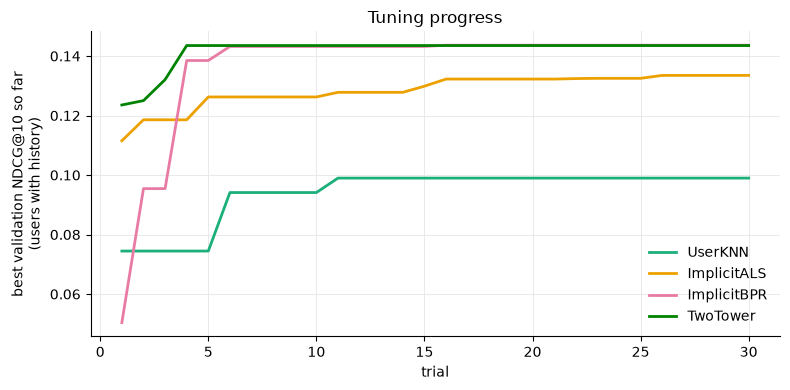

In [8]:
# Best validation NDCG so far after each trial: if a curve is still rising at the end, the budget was too small
fig, ax = plt.subplots(figsize=(8, 4))
for name, study in studies.items():
    values = [t.value for t in study.trials if t.value is not None]
    ax.plot(range(1, len(values) + 1), np.maximum.accumulate(values), color=COLORS[name], label=name)
ax.set_xlabel("trial")
ax.set_ylabel("best validation NDCG@10 so far\n(users with history)")
ax.set_title("Tuning progress")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

YAML snippet with the best hyperparameters, to be copied into the `models` section of `config.yaml`
(this notebook does not change the config).

In [9]:
def plain(value):
    # numpy numbers -> Python numbers for YAML
    return value.item() if hasattr(value, "item") else value

snippet = {tuning.MODELS[name].config_key: {key: plain(value) for key, value in study.best_params.items()}
           for name, study in studies.items()}
for key in ["implicit_als", "implicit_bpr", "two_tower"]:   # not tuned, but part of the config entry
    if key in snippet:
        snippet[key]["positive_threshold"] = THRESHOLD
print(yaml.safe_dump({"models": snippet}, sort_keys=False))

models:
  user_knn:
    k: 131
    similarity_measure: pearson
    gamma: 100
    min_support: 100
  implicit_als:
    factors: 16
    regularization: 0.001306757868853338
    alpha: 1.1514741512677193
    iterations: 6
    positive_threshold: 4
  implicit_bpr:
    factors: 99
    learning_rate: 0.0012368429194827427
    regularization: 8.597755025873098e-05
    iterations: 127
    positive_threshold: 4
  two_tower:
    dim: 64
    embedding_dim: 32
    hidden: 256
    epochs: 9
    batch_size: 1024
    learning_rate: 0.0003646439558980723
    weight_decay: 5.169879442298538e-06
    temperature: 0.0314799191252873
    id_dropout: 0.40109849037701983
    positive_threshold: 4



### 1b. TwoTower: training curve

The best TwoTower configuration trained for 20 epochs, with the training loss and the validation NDCG@10 after
every epoch. This shows whether the tuned number of epochs is in a sensible place (still on validation only).

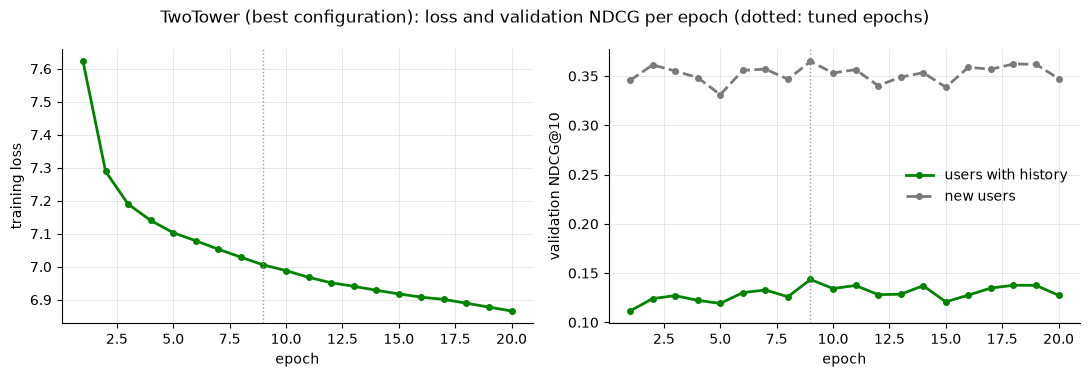

,epoch,ndcg_warm,ndcg_cold,loss
0,1,0.111501,0.345528,7.622079
1,2,0.124123,0.361293,7.288791
2,3,0.127079,0.355101,7.189623
3,4,0.122339,0.348441,7.140315
4,5,0.119249,0.331099,7.102854
5,6,0.130157,0.355731,7.078757
6,7,0.132862,0.357029,7.052964
7,8,0.125954,0.346801,7.028918
8,9,0.143524,0.364780,7.005302
9,10,0.134288,0.353186,6.988278


In [10]:
tt_params = dict(studies["TwoTower"].best_params) if "TwoTower" in studies else tuning.final_params("TwoTower", cfg)
tt_params["epochs"] = 20
curve = []

def after_epoch(epoch, model):
    metrics = evaluate_recommender(model, s.train.ratings, s.val.ratings, CATALOGUE, K, THRESHOLD)
    curve.append({"epoch": epoch, "ndcg_warm": metrics["ndcg_warm"], "ndcg_cold": metrics.get("ndcg_cold")})

model = TwoTower(**tt_params, seed=SEED, on_epoch_end=after_epoch)
model.train(s.train)
curve = pd.DataFrame(curve).assign(loss=model.losses)

# Two measures with different scales -> two panels, not two y-axes
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(curve["epoch"], curve["loss"], color=COLORS["TwoTower"], marker="o", markersize=4)
axes[0].set_ylabel("training loss")
axes[1].plot(curve["epoch"], curve["ndcg_warm"], color=COLORS["TwoTower"], marker="o", markersize=4,
             label="users with history")
axes[1].plot(curve["epoch"], curve["ndcg_cold"], color="#7a7a7a", marker="o", markersize=4, linestyle="--",
             label="new users")
axes[1].set_ylabel("validation NDCG@10")
axes[1].legend(frameon=False)
best_epochs = studies["TwoTower"].best_params["epochs"] if "TwoTower" in studies else None
for ax in axes:
    ax.set_xlabel("epoch")
    if best_epochs:
        ax.axvline(best_epochs, color="#999999", linewidth=1, linestyle=":")
fig.suptitle("TwoTower (best configuration): loss and validation NDCG per epoch (dotted: tuned epochs)")
plt.tight_layout()
plt.show()
curve